# Spatial variability

This notebook is still being developed. 

In [199]:
import numpy as np
import xarray as xr
import rioxarray  # noqa: F401
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from seaborn import set_theme
set_theme()

import sys
import os
from pathlib import Path

# import from this repo 
project_root = str(Path(os.getcwd()).parent)
if project_root not in sys.path:
    sys.path.append(project_root)

%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


First, we setup logging to get useful information and error messages. 

In [200]:
import logging

logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True 
)

Open the data cubes that were saved by the $\gamma_{snow}$ notebook. 

In [201]:
data_dir = "../data/"

nisar_20m = xr.open_zarr(data_dir + 'nisar/zarrs/snow_20m.zarr')
nisar_80m = xr.open_zarr(data_dir + 'nisar/zarrs/snow_80m.zarr')

In [202]:
# nisar_80m['gamma_snow_80div20'] = nisar_80m['gamma_snow_80div20'].where(nisar_80m['gamma_snow_80div20'] <= 1.3, np.nan)
# nisar_80m['gamma_snow'] = nisar_80m['gamma_snow'].where(nisar_80m['gamma_snow'] <= 1.3, np.nan)
# nisar_20m['gamma_snow'] = nisar_20m['gamma_snow'].where(nisar_20m['gamma_snow'] <= 1.3, np.nan)

# nisar_80m['gamma_snow_80div20'] = nisar_80m['gamma_snow_80div20'].clip(min=0, max=1)
# nisar_80m['gamma_snow'] = nisar_80m['gamma_snow'].clip(min=0, max=1)
# nisar_20m['gamma_snow'] = nisar_20m['gamma_snow'].clip(min=0, max=1)

In [203]:
starts = nisar_80m.start 
ends = nisar_80m.end

zoom_box = {
    'x': (min(nisar_80m['x'].values), 325000),
    'y': (4307500, 4320500),
    }

In [204]:
aso_3m = rioxarray.open_rasterio(
    data_dir + 'aso/er_20260318/ASO_EastRiver_2026Mar18_snowdepth_3m.tif',
    masked=True, chunks={'x': 2048, 'y': 2048},
).squeeze(drop=True)
# smooth to 9m boxes 
aso_3m = aso_3m.rio.reproject(aso_3m.rio.crs, resolution=9, resampling=Resampling.average)

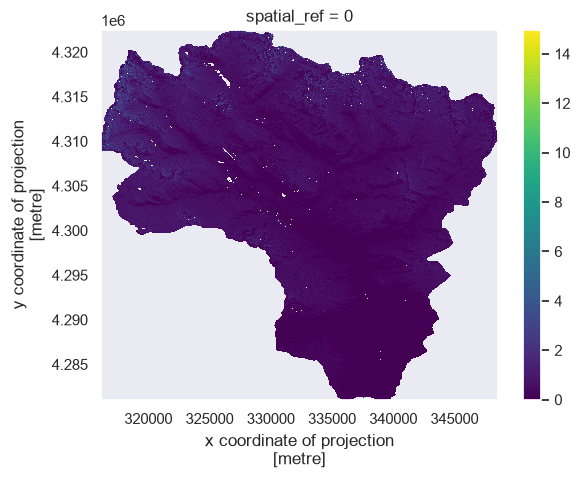

In [205]:
aso_3m.plot()

In [206]:
def aso_variance_80m(depth_3m, target):
    """Variance of 3 m snow depth within each target pixel, via Var = E[x^2] - E[x]^2.

    Block averaging ignores NaNs, so only valid ASO pixels contribute.
    """
    mean = depth_3m.rio.reproject_match(target, resampling=Resampling.average)
    mean_sq = (depth_3m ** 2).rio.reproject_match(target, resampling=Resampling.average)
    var = (mean_sq - mean ** 2).clip(min=0)  # clip tiny negative values from round-off
    valid = depth_3m.notnull().astype('float32').rio.reproject_match(target, resampling=Resampling.average)
    # turn into sample variance by multiplying by n/(n-1) where n is the number of valid pixels
    # num_valid = valid.where(valid > 0, valid * target.rio.resolution()[0]**2)  # number of valid pixels in each target pixel
    # var = var * (num_valid / (num_valid - 1)).clip(min=0)
    return mean, var, valid

In [207]:
target = nisar_80m['elevation'].rio.write_crs(nisar_80m.rio.crs)
aso_mean, aso_var, aso_valid = aso_variance_80m(aso_3m, target)

In [208]:
nisar_80m['aso_depth_mean'] = aso_mean.drop_vars('spatial_ref')
nisar_80m['aso_depth_var'] = aso_var.where(aso_valid > 0.5).drop_vars('spatial_ref') 
nisar_80m['aso_depth_var'].attrs = {'long_name': 'ASO snow depth variance within 80 m pixel', 'units': 'm^2'}

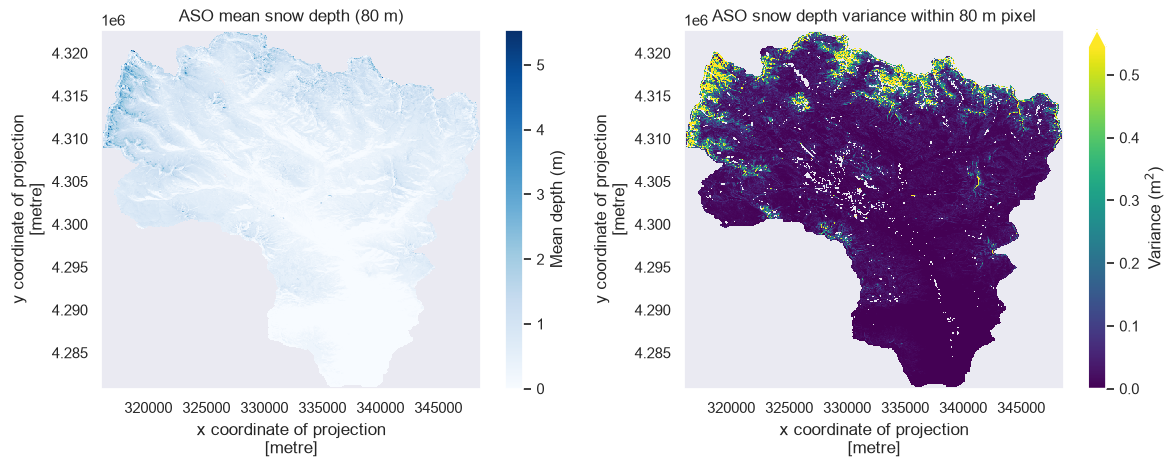

In [209]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
nisar_80m['aso_depth_mean'].plot(ax=axes[0], cmap='Blues', cbar_kwargs={'label': 'Mean depth (m)'})
nisar_80m['aso_depth_var'].plot(ax=axes[1], cmap='viridis', robust=True, cbar_kwargs={'label': 'Variance (m$^2$)'})
axes[0].set_title('ASO mean snow depth (80 m)')
axes[1].set_title('ASO snow depth variance within 80 m pixel')
plt.tight_layout()

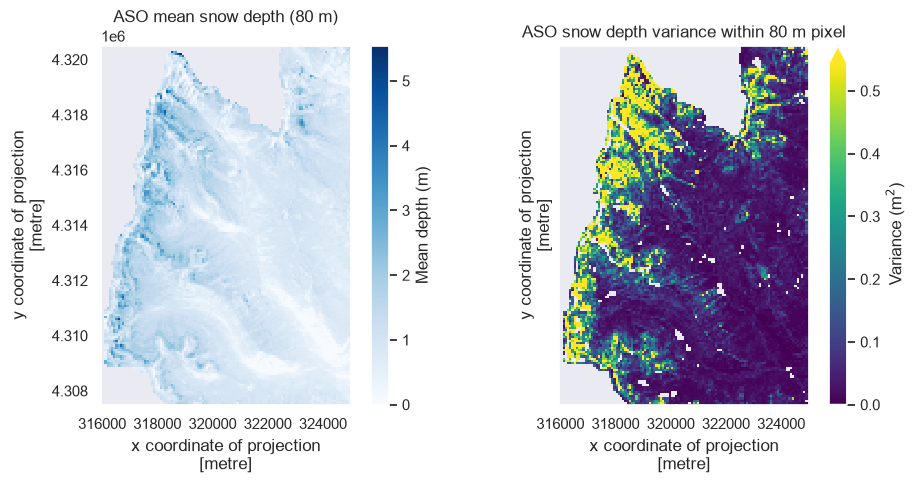

In [210]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)

nisar_80m['aso_depth_mean'].plot(ax=axes[0], cmap='Blues', cbar_kwargs={'label': 'Mean depth (m)'})
nisar_80m['aso_depth_var'].plot(ax=axes[1], cmap='viridis', robust=True, cbar_kwargs={'label': 'Variance (m$^2$)'})
axes[0].set_title('ASO mean snow depth (80 m)')
axes[1].set_title('ASO snow depth variance within 80 m pixel')

for ax in axes:
    ax.set_xlim(zoom_box['x'])
    ax.set_ylim(zoom_box['y'])
    ax.set_aspect('equal')

plt.tight_layout()

In [211]:
wet = starts > np.datetime64('2026-02-20')
accum_pair = '20260215_20260227'

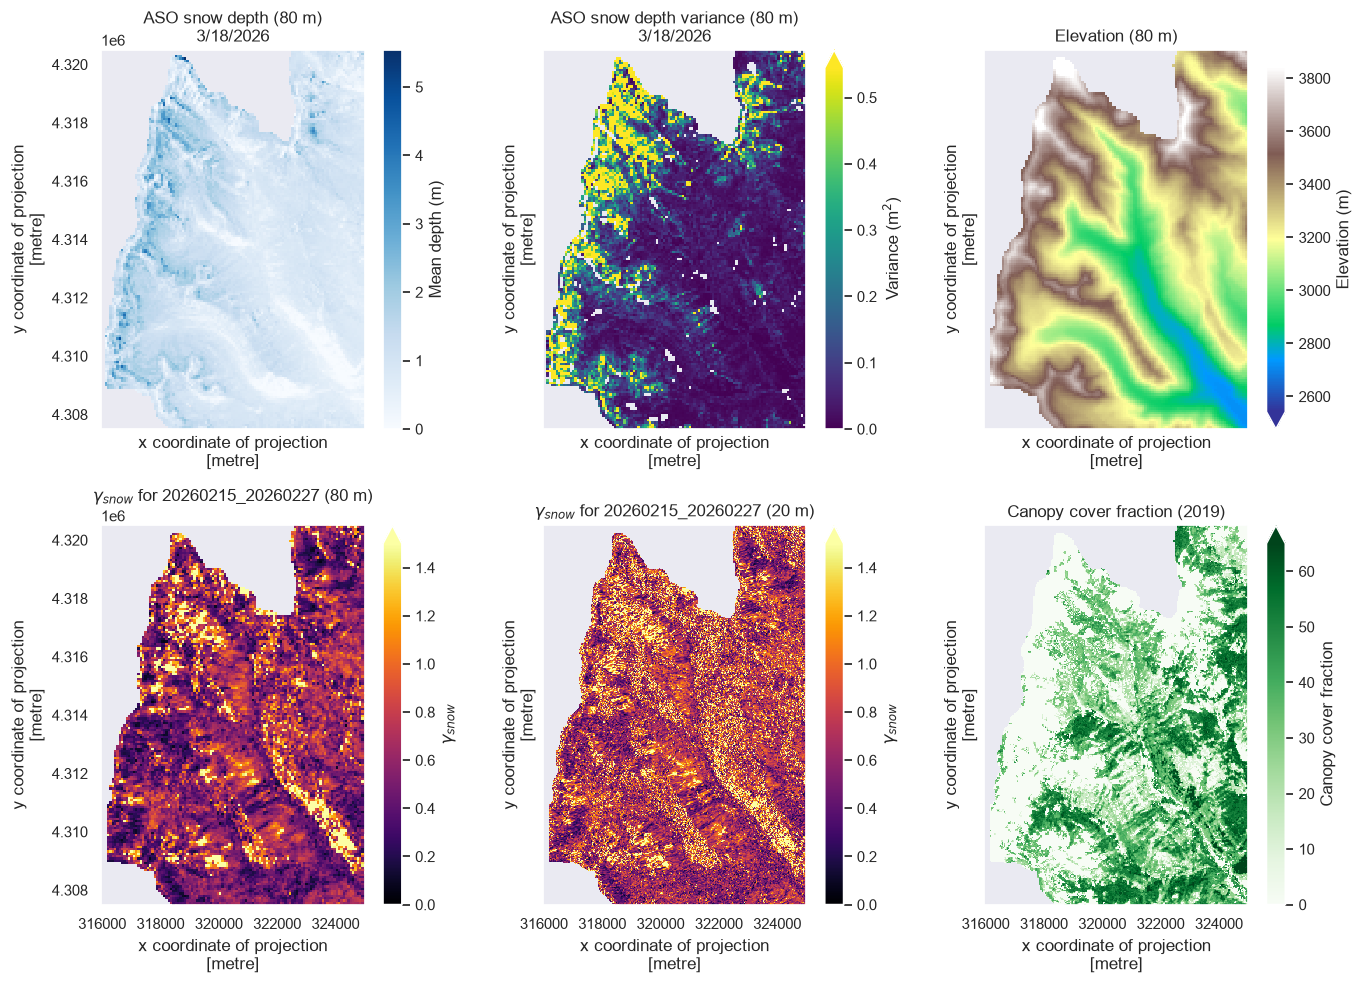

In [213]:
fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharey=True, sharex=True)

gamma_snow_dry = nisar_80m['gamma_snow'].where(~wet).mean(dim='pair')

nisar_80m['aso_depth_mean'].plot(ax=axes[0, 0], cmap='Blues', cbar_kwargs={'label': 'Mean depth (m)'})
nisar_80m['aso_depth_var'].plot(ax=axes[0, 1], cmap='viridis', robust=True, cbar_kwargs={'label': 'Variance (m$^2$)'})
nisar_80m['elevation'].plot(ax=axes[0, 2], cmap='terrain', robust=True, cbar_kwargs={'label': 'Elevation (m)'})

# gamma_snow_dry.plot(ax=axes[0, 1], cmap='inferno', robust=True, cbar_kwargs={'label': 'Mean $\gamma_{snow}$'}, vmin=0, vmax=1)
nisar_80m.sel(pair=accum_pair)['gamma_snow'].plot(ax=axes[1, 0], cmap='inferno', robust=True, cbar_kwargs={'label': '$\gamma_{snow}$'}, vmin=0, vmax=1.5)
nisar_20m.sel(pair=accum_pair)['gamma_snow'].plot(ax=axes[1, 1], cmap='inferno', robust=True, cbar_kwargs={'label': '$\gamma_{snow}$'}, vmin=0, vmax=1.5)
nisar_20m.sel(pair=accum_pair)['canopy_2019'].plot(ax=axes[1, 2], cmap='Greens', robust=True, cbar_kwargs={'label': 'Canopy cover fraction'})

axes[0, 0].set_title('ASO snow depth (80 m)\n3/18/2026')
axes[0, 1].set_title('ASO snow depth variance (80 m)\n3/18/2026')
axes[0, 2].set_title('Elevation (80 m)')
axes[1, 0].set_title('$\gamma_{snow}$' + f' for {accum_pair} (80 m)')
axes[1, 1].set_title('$\gamma_{snow}$' + f' for {accum_pair} (20 m)')
axes[1, 2].set_title('Canopy cover fraction (2019)')

for ax in axes.flatten():
    ax.set_xlim(zoom_box['x'])
    ax.set_ylim(zoom_box['y'])

    ax.set_aspect('equal')

plt.tight_layout()

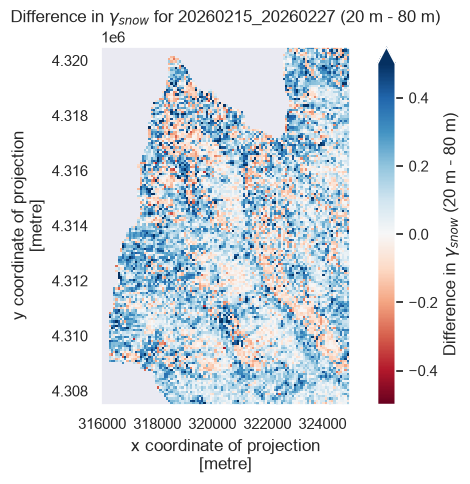

In [196]:
diff = nisar_20m.sel(pair=accum_pair)['gamma_snow'].rio.reproject_match(nisar_80m['gamma_snow'], resampling=Resampling.bilinear) - nisar_80m.sel(pair=accum_pair)['gamma_snow']

fig, ax = plt.subplots(figsize=(6, 5))
diff.plot(ax=ax, cmap='RdBu', robust=True, cbar_kwargs={'label': 'Difference in $\gamma_{snow}$ (20 m - 80 m)'}, vmin=-0.5, vmax=0.5)
ax.set_title('Difference in $\gamma_{snow}$' + f' for {accum_pair} (20 m - 80 m)')
ax.set_xlim(zoom_box['x'])
ax.set_ylim(zoom_box['y'])
ax.set_aspect('equal')

plt.tight_layout()
plt.show()

214840 214840 214840


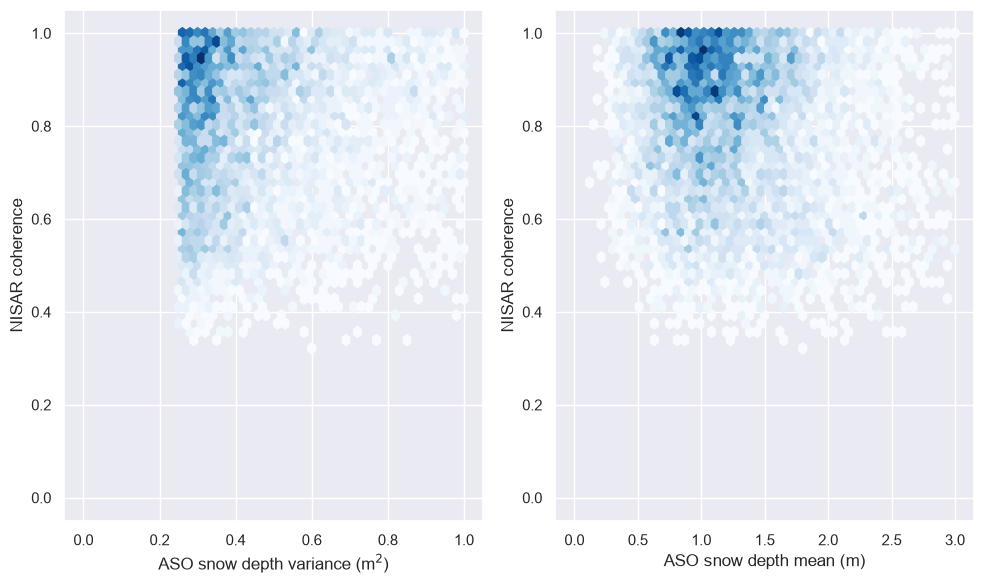

In [183]:
# scatter average ASO variance vs NISAR coherence 
# slice by zoom_box 
nisar_subset = nisar_80m.sel(x=slice(*zoom_box['x']), y=slice(zoom_box['y'][1], zoom_box['y'][0]))
nisar_subset = nisar_80m.where(nisar_80m['aso_depth_var'] > 0.25)

fig, ax = plt.subplots(1, 2, figsize=(10, 6))
x1 = nisar_subset['aso_depth_var'].values.flatten()
x2 = nisar_subset['aso_depth_mean'].values.flatten()
y = nisar_subset['gamma_snow'].mean(dim='pair').where(~nisar_subset['aso_depth_var'].isnull()).values.flatten()
print(len(x1), len(x2), len(y))

ax[0].hexbin(x1, y, gridsize=50, cmap='Blues', mincnt=1, extent=(0, 1, 0, 1))
ax[1].hexbin(x2, y, gridsize=50, cmap='Blues', mincnt=1, extent=(0, 3, 0, 1))
ax[0].set_xlabel('ASO snow depth variance (m$^2$)')
ax[0].set_ylabel('NISAR coherence')
ax[1].set_xlabel('ASO snow depth mean (m)')
ax[1].set_ylabel('NISAR coherence')

# ax[0].set_ylim(0, 1)
# ax[1].set_ylim(0, 1)
# ax[0].set_xlim(0, 1)
# ax[1].set_xlim(0, 2)

plt.tight_layout()
plt.show()